In [1]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tree.xg_classifier import XGClassifier
from xgboost import XGBClassifier, plot_tree
import shap
from common.helper import load_data_and_scale_pos_weight
from mini_shap.independent_tree_shap import IndependentTreeExplainer
from tree.xg_classifier import XGClassifier
from common.helper import *

/home/sakane/Documents/projects/python/mini_xgshap/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
both_bin_path = "../datasets/BRFSS/feat_eng/both_bin.parquet"
both_grp_path = "../datasets/BRFSS/feat_eng/both_grp.parquet"
both_og_path = "../datasets/BRFSS/feat_eng/both_og.parquet"

both_bin_model_path = "../datasets/BRFSS/feat_eng/models/both_bin_model.ubj"
both_grp_model_path = "../datasets/BRFSS/feat_eng/models/both_grp_model.ubj"
both_og_model_path = "../datasets/BRFSS/feat_eng/models/both_og_model.ubj"

both_bin_shap_path = "../datasets/BRFSS/feat_eng/shap_values/expl_both_bin_shap_values.npy"
both_og_shap_path = "../datasets/BRFSS/feat_eng/shap_values/expl_both_og_shap_values.npy"
both_grp_shap_path = "../datasets/BRFSS/feat_eng/shap_values/expl_both_grp_shap_values.npy"


In [3]:
X_both_og_train, X_both_og_test, y_both_og_train, y_both_og_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True, dataset_path=both_og_path)
X_both_og_train_np, X_both_og_test_np, y_both_og_train_np, y_both_og_test_np = X_both_og_train.to_numpy().astype(np.float32), X_both_og_test.to_numpy().astype(np.float32), y_both_og_train.to_numpy().astype(np.float32), y_both_og_test.to_numpy().astype(np.float32)

X_both_grp_train, X_both_grp_test, y_both_grp_train, y_both_grp_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True, dataset_path=both_grp_path)
X_both_grp_train_np, X_both_grp_test_np, y_both_grp_train_np, y_both_grp_test_np = X_both_grp_train.to_numpy().astype(np.float32), X_both_grp_test.to_numpy().astype(np.float32), y_both_grp_train.to_numpy().astype(np.float32), y_both_grp_test.to_numpy().astype(np.float32)

X_both_bin_train, X_both_bin_test, y_both_bin_train, y_both_bin_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True, dataset_path=both_bin_path)
X_both_bin_train_np, X_both_bin_test_np, y_both_bin_train_np, y_both_bin_test_np = X_both_bin_train.to_numpy().astype(np.float32), X_both_bin_test.to_numpy().astype(np.float32), y_both_bin_train.to_numpy().astype(np.float32), y_both_bin_test.to_numpy().astype(np.float32)


In [4]:
both_og_model = XGBClassifier()
both_og_model.load_model(both_og_model_path)
both_og_model2 = XGClassifier.load_from_xgbclassifier(both_og_model, columns=list(X_both_og_train.columns))

both_bin_model = XGBClassifier()
both_bin_model.load_model(both_bin_model_path)
both_bin_model2 = XGClassifier.load_from_xgbclassifier(both_bin_model, columns=list(X_both_bin_train.columns))

both_grp_model = XGBClassifier()
both_grp_model.load_model(both_grp_model_path)
both_grp_model2 = XGClassifier.load_from_xgbclassifier(both_grp_model, columns=list(X_both_grp_train.columns))

In [5]:
ev_both_grp, sv_both_grp = load_shap_values(both_grp_shap_path)
ev_both_bin, sv_both_bin = load_shap_values(both_bin_shap_path)
ev_both_og, sv_both_og = load_shap_values(both_og_shap_path)

In [6]:
both_og_pred_raw = both_og_model.predict(X_both_og_test, output_margin=True)
both_grp_pred_raw = both_grp_model.predict(X_both_grp_test, output_margin=True)
both_bin_pred_raw = both_bin_model.predict(X_both_bin_test, output_margin=True)

In [7]:
both_og_mask = np.isclose(both_og_pred_raw, ev_both_og + sv_both_og.sum(1), rtol=0.0, atol=1e-4)
both_bin_mask = np.isclose(both_bin_pred_raw, ev_both_bin + sv_both_bin.sum(1), rtol=0.0, atol=1e-4)
both_grp_mask = np.isclose(both_grp_pred_raw, ev_both_grp + sv_both_grp.sum(1), rtol=0.0, atol=1e-4)

In [8]:
assert(both_og_mask.sum() == len(both_og_pred_raw))
assert(both_bin_mask.sum() == len(both_bin_pred_raw))
assert(both_grp_mask.sum() == len(both_grp_pred_raw))

In [9]:
both_og_expl = shap.Explanation(
    values=sv_both_og,
    base_values=ev_both_og,
    data=X_both_og_test_np,
    feature_names=X_both_og_train.columns,
)

both_bin_expl = shap.Explanation(
    values=sv_both_bin,
    base_values=ev_both_bin,
    data=X_both_bin_test_np,
    feature_names=X_both_bin_train.columns,
)

both_grp_expl = shap.Explanation(
    values=sv_both_grp,
    base_values=ev_both_grp,
    data=X_both_grp_test_np,
    feature_names=X_both_grp_train.columns,
)

In [10]:
X_both_og_test_replace_missing = X_both_og_test_np.copy()
X_both_og_test_replace_missing[np.isnan(X_both_og_test_replace_missing)] = -1

X_both_bin_test_replace_missing = X_both_bin_test_np.copy()
X_both_bin_test_replace_missing[np.isnan(X_both_bin_test_replace_missing)] = -1

X_both_grp_test_replace_missing = X_both_grp_test_np.copy()
X_both_grp_test_replace_missing[np.isnan(X_both_grp_test_replace_missing)] = -1

In [11]:
replace_missing_both_og_expl = shap.Explanation(
    values=sv_both_og,
    base_values=ev_both_og,
    data=X_both_og_test_replace_missing,
    feature_names=X_both_og_train.columns,
)

replace_missing_both_bin_expl = shap.Explanation(
    values=sv_both_bin,
    base_values=ev_both_bin,
    data=X_both_bin_test_replace_missing,
    feature_names=X_both_bin_train.columns,
)

replace_missing_both_grp_expl = shap.Explanation(
    values=sv_both_grp,
    base_values=ev_both_grp,
    data=X_both_grp_test_replace_missing,
    feature_names=X_both_grp_train.columns,
)

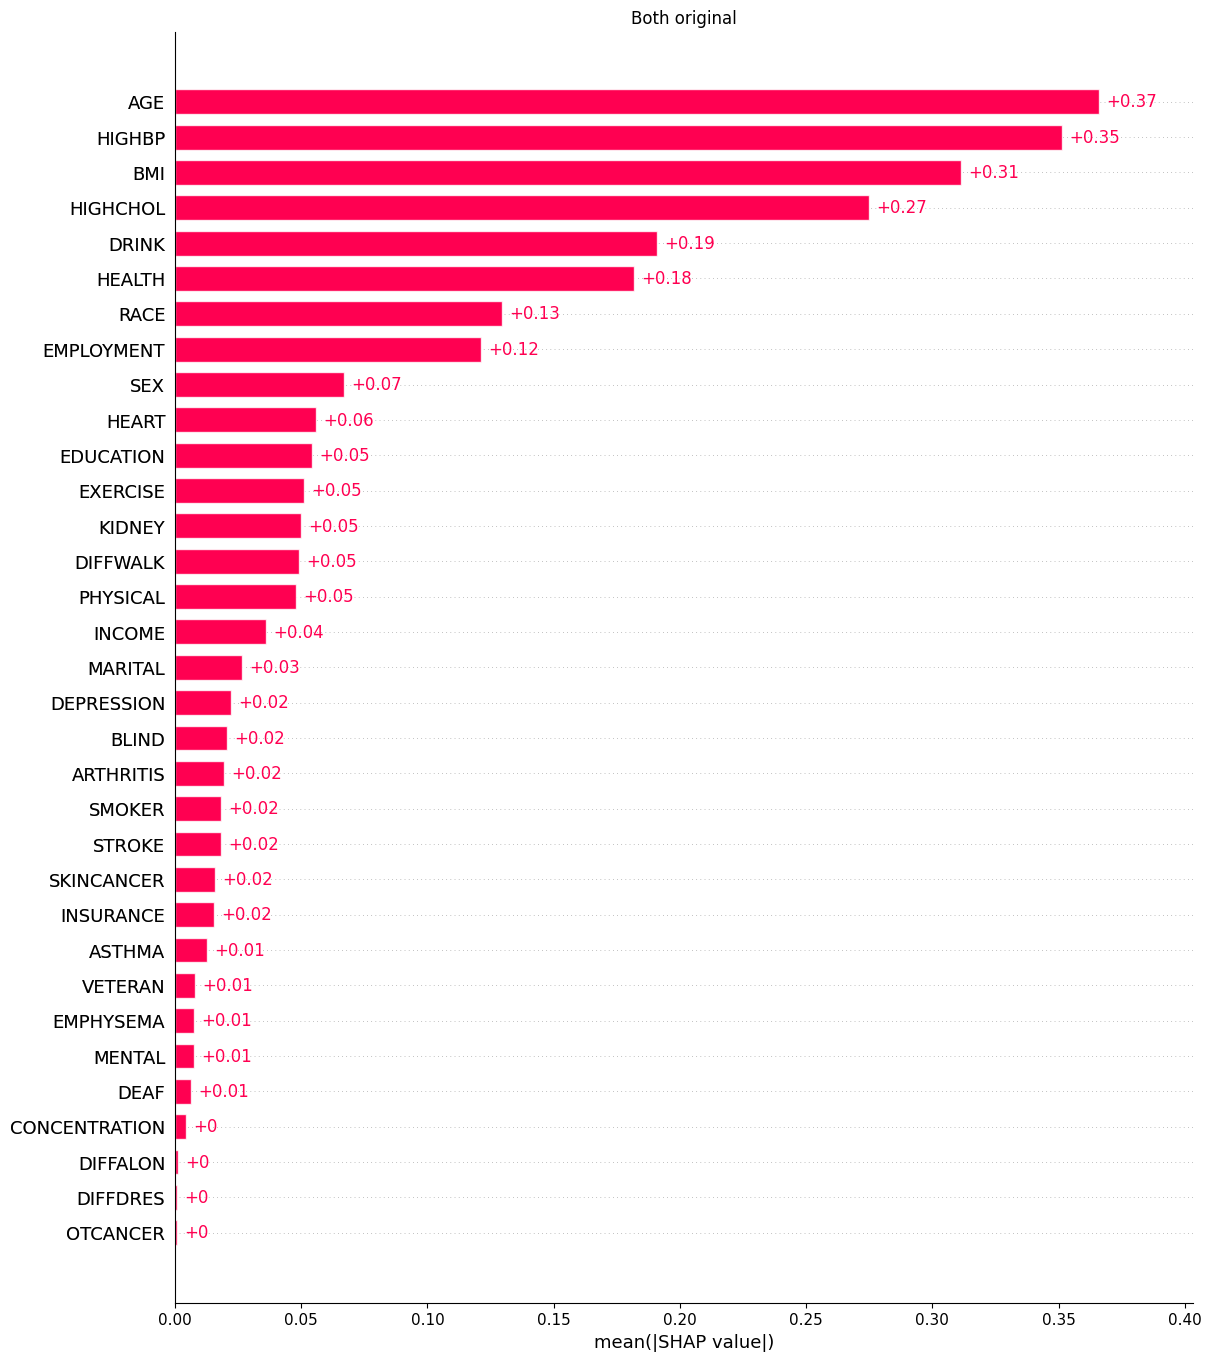

In [12]:
fig, ax = plt.subplots(nrows=1, 
                        ncols=1, 
                        sharex=False, 
                        sharey=False,
                        layout="constrained",
                        figsize=(12.0, 13.5)
                    )

ax.set_title("Both original")
shap.plots.bar(both_og_expl, max_display=len(X_both_og_train.columns), ax=ax)

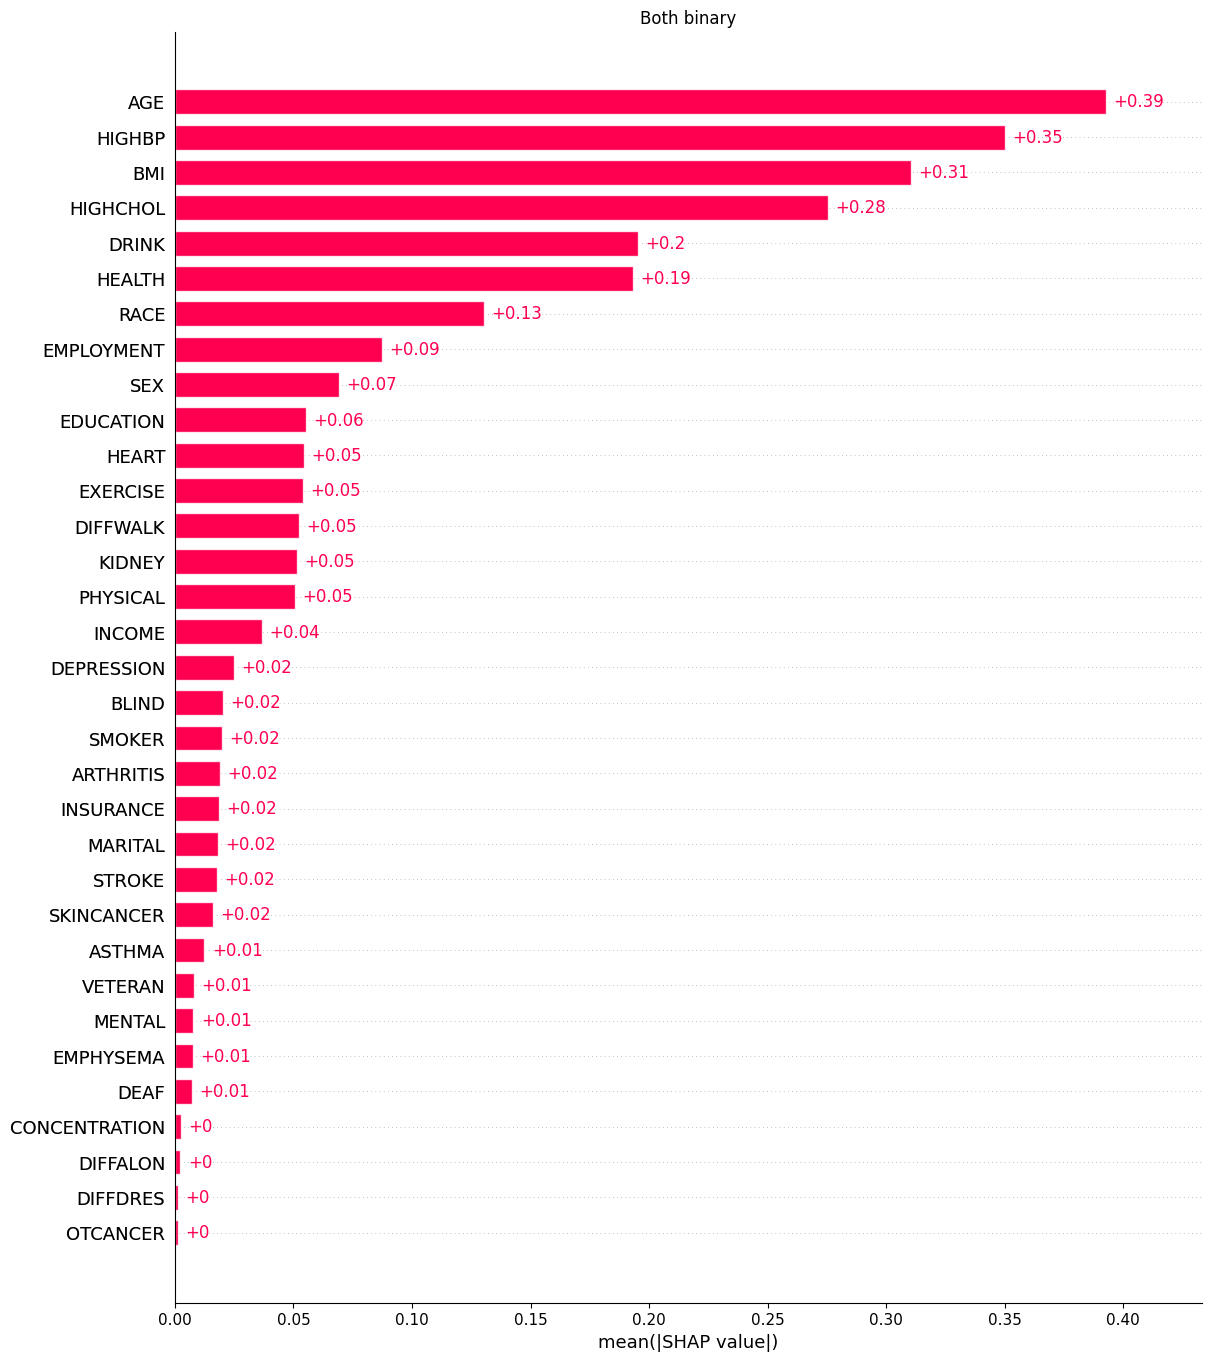

In [13]:
fig, ax = plt.subplots(nrows=1, 
                        ncols=1, 
                        sharex=False, 
                        sharey=False,
                        layout="constrained",
                        figsize=(12.0, 13.5)
                    )

ax.set_title("Both binary")
shap.plots.bar(both_bin_expl, max_display=len(X_both_bin_train.columns), ax=ax)

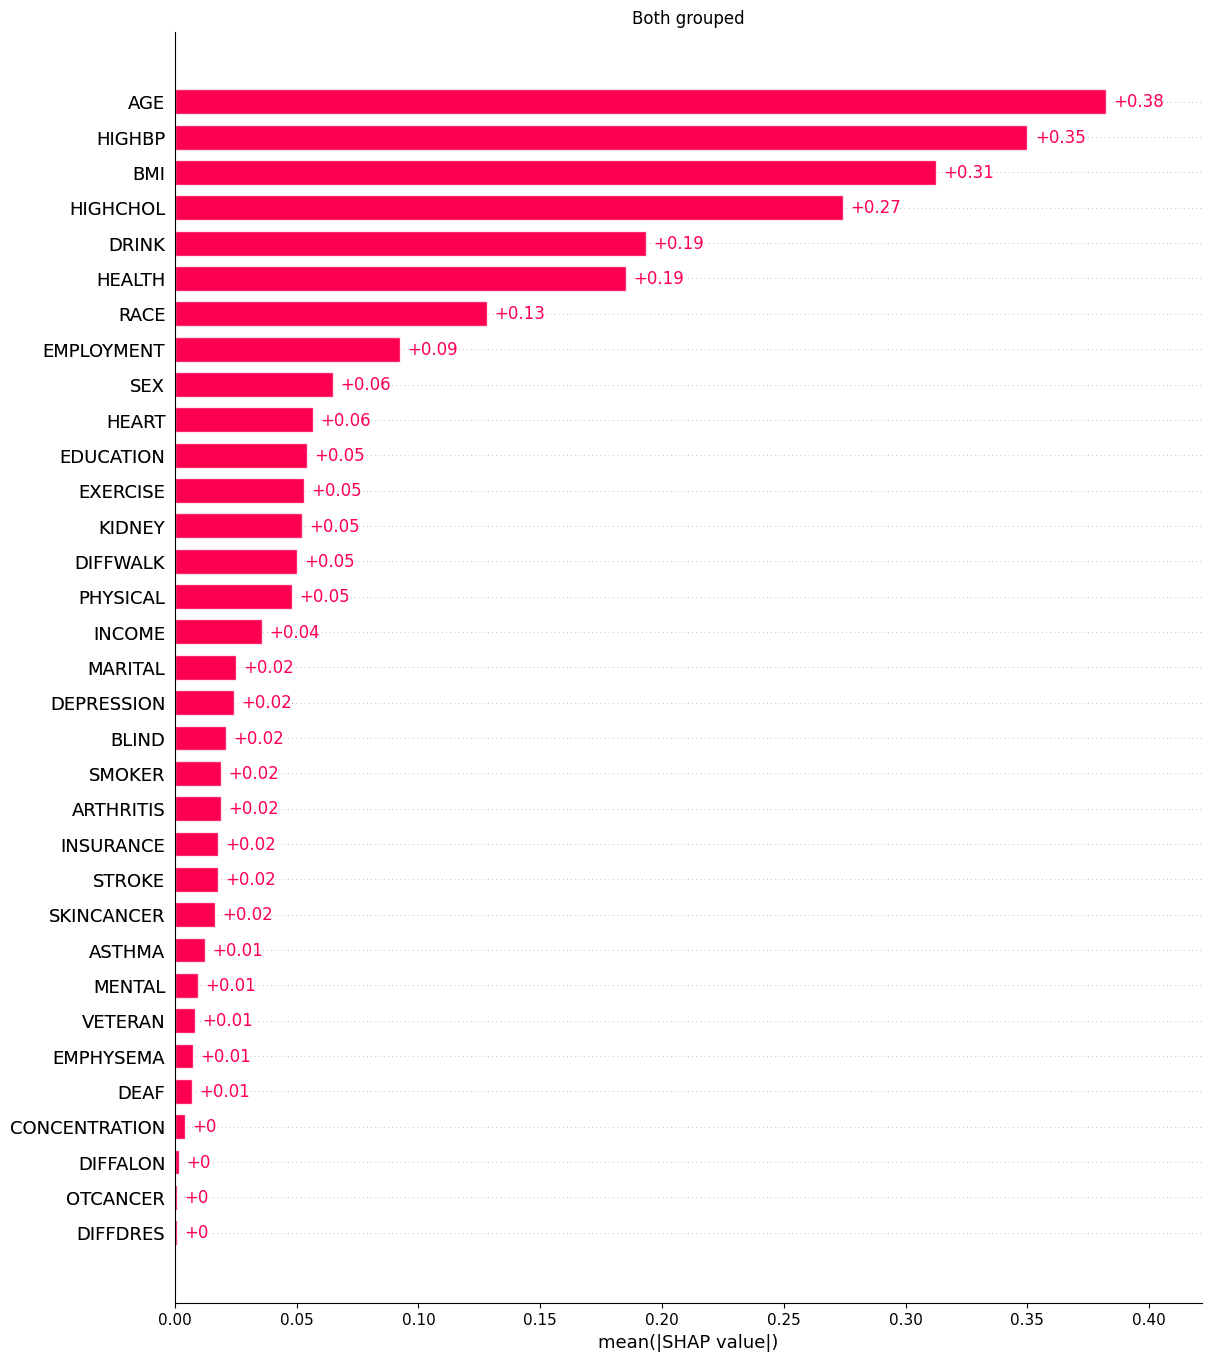

In [14]:
fig, ax = plt.subplots(nrows=1, 
                        ncols=1, 
                        sharex=False, 
                        sharey=False,
                        layout="constrained",
                        figsize=(12.0, 13.5)
                    )

ax.set_title("Both grouped")
shap.plots.bar(both_grp_expl, max_display=len(X_both_grp_train.columns), ax=ax)

[Text(-1, 0, 'Missing'), Text(0, 0, 'Not Married'), Text(1, 0, 'Married')]

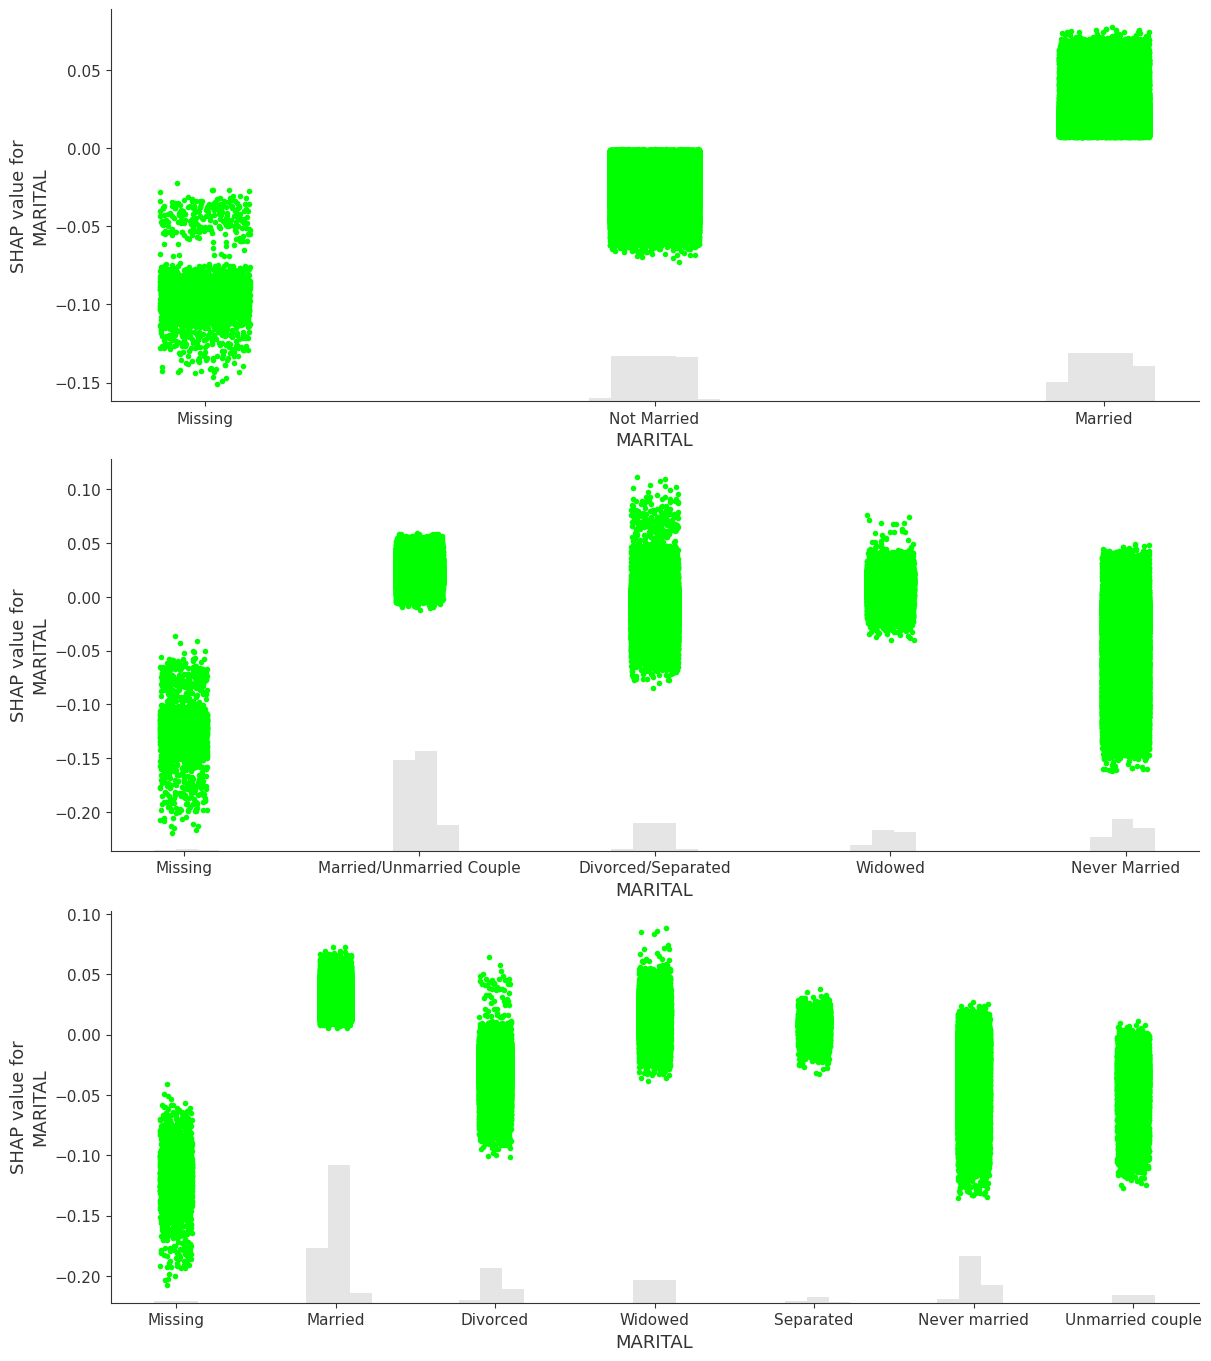

In [15]:
fig = plt.figure(layout="constrained", figsize=(12.0, 13.5))
gs = plt.GridSpec(nrows=3, ncols=1, figure=fig)
axs = []

for i in range(gs.nrows):
    if i == gs.nrows - 1:
        axs.append(fig.add_subplot(gs[i, :]))
        continue

    for j in range(gs.ncols):
        axs.append(fig.add_subplot(gs[i, j]))

shap.plots.scatter(
    replace_missing_both_og_expl[:, "MARITAL"],
    ax=axs[2],
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_both_grp_expl[:, "MARITAL"],
    ax=axs[1],
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_both_bin_expl[:, "MARITAL"],
    ax=axs[0],
    show=False,
    color='lime',
)

axs[2].set_xticks([-1, 0, 1, 2, 3, 4, 5])
axs[2].set_xticklabels(["Missing", "Married", "Divorced", "Widowed", "Separated", "Never married", "Unmarried couple"])

axs[1].set_xticks([-1, 0, 1, 2, 3])
axs[1].set_xticklabels(["Missing", "Married/Unmarried Couple", "Divorced/Separated", "Widowed", "Never Married"])

axs[0].set_xticks([-1, 0, 1])
axs[0].set_xticklabels(["Missing", "Not Married", "Married"])

[Text(-1, 0, 'Missing'), Text(0, 0, 'Unemployed'), Text(1, 0, 'Employed')]

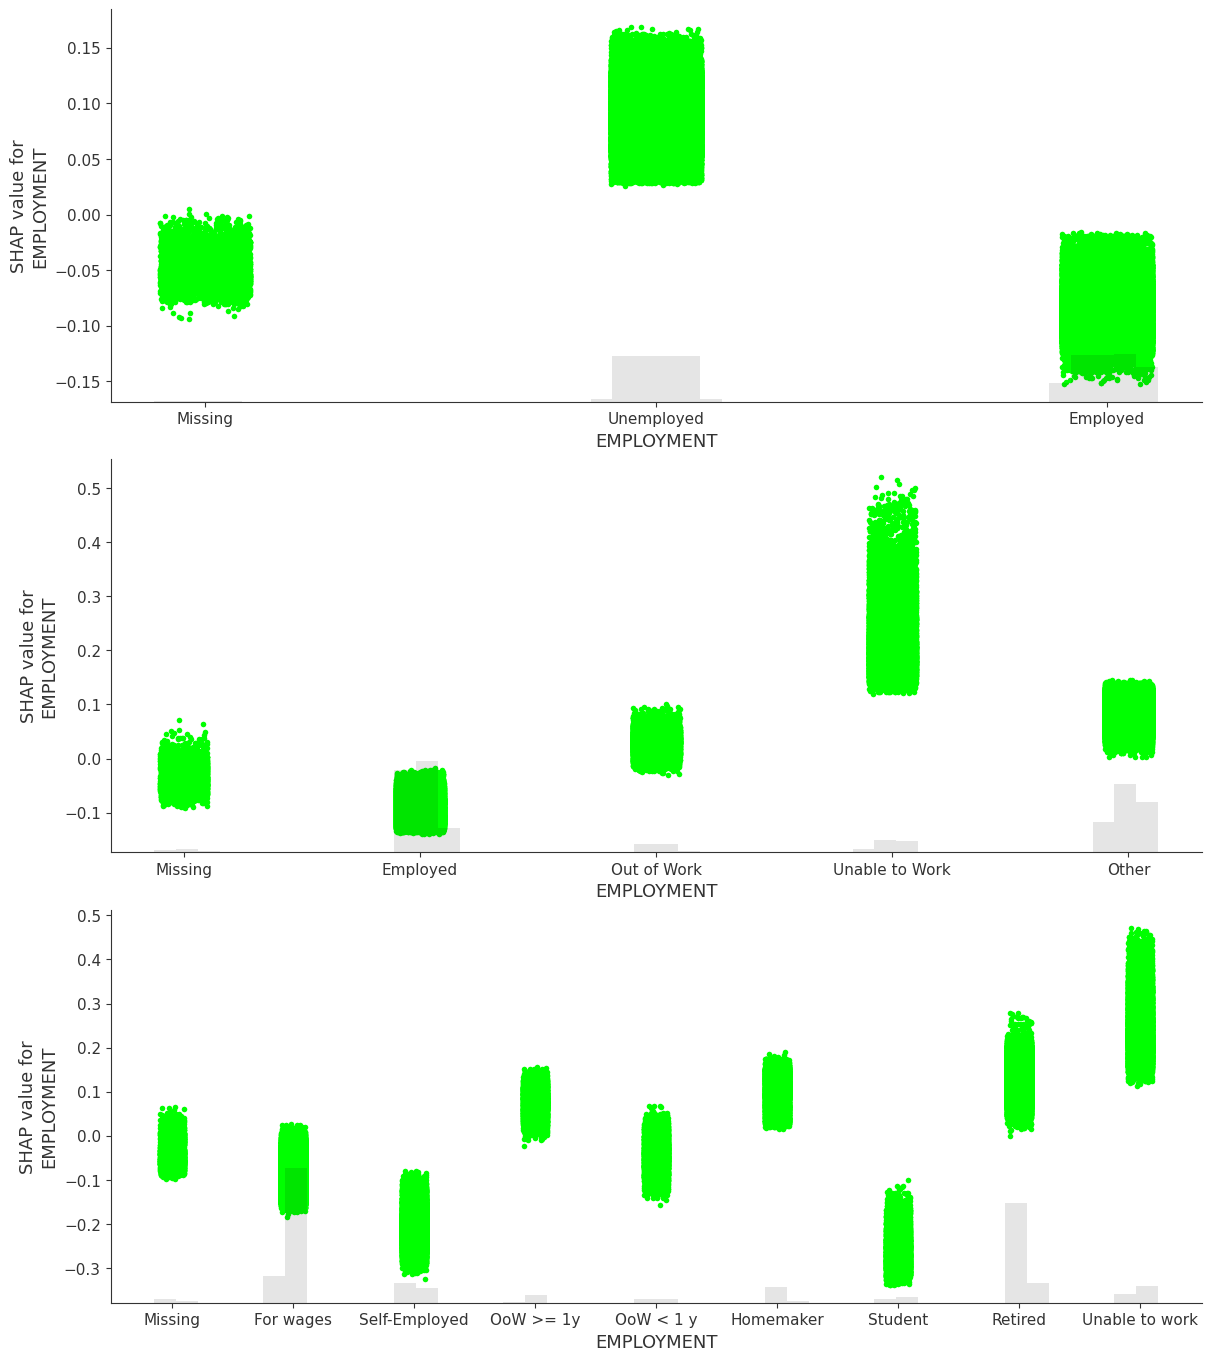

In [16]:
fig = plt.figure(layout="constrained", figsize=(12.0, 13.5))
gs = plt.GridSpec(nrows=3, ncols=1, figure=fig)
axs = []

for i in range(gs.nrows):
    if i == gs.nrows - 1:
        axs.append(fig.add_subplot(gs[i, :]))
        continue

    for j in range(gs.ncols):
        axs.append(fig.add_subplot(gs[i, j]))

shap.plots.scatter(
    replace_missing_both_og_expl[:, "EMPLOYMENT"],
    ax=axs[2],
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_both_grp_expl[:, "EMPLOYMENT"],
    ax=axs[1],
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_both_bin_expl[:, "EMPLOYMENT"],
    ax=axs[0],
    show=False,
    color='lime',
)

axs[2].set_xticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
axs[2].set_xticklabels(["Missing", "For wages", "Self-Employed", "OoW >= 1y", "OoW < 1 y", "Homemaker", "Student", "Retired", "Unable to work"])

axs[1].set_xticks([-1, 0, 1, 2, 3])
axs[1].set_xticklabels(["Missing", "Employed", "Out of Work", "Unable to Work", "Other"])

axs[0].set_xticks([-1, 0, 1])
axs[0].set_xticklabels(["Missing", "Unemployed", "Employed"])

In [42]:
def cat_table(labels, shap_vals):
    d = pd.DataFrame({"cat": labels, "shap": shap_vals})
    return (d.groupby("cat").shap
              .agg(n="size", mean="mean",
                   q25=lambda x: x.quantile(.25),
                   q75=lambda x: x.quantile(.75))
              .sort_values("mean"))

def share(shap_vals, labels):
    d = pd.DataFrame({"s": shap_vals, "g": labels})
    m = d.s.mean()
    ssb = d.groupby("g").s.apply(lambda x: len(x) * (x.mean() - m) ** 2).sum()
    return ssb / ((d.s - m) ** 2).sum()

In [48]:
emp_og_labels = ["Missing", "For wages", "Self-Employed", "OoW >= 1y", "OoW < 1 y", "Homemaker", "Student", "Retired", "Unable to work"]
emp_og_code = [-1, 0, 1, 2, 3, 4, 5, 6, 7]

emp_og_code_labels_dict = {
    k: v for k, v in zip(emp_og_code, emp_og_labels)
}

emp_grp_labels = ["Missing", "Employed", "Out of Work", "Unable to Work", "Other"]
emp_grp_code = [-1, 0, 1, 2, 3]

emp_grp_code_labels_dict = {
    k: v for k, v in zip(emp_grp_code, emp_grp_labels)
}

emp_bin_labels = ["Missing", "Unmployed", "Employed"]
emp_bin_code = [-1, 0, 1]

emp_bin_code_labels_dict = {
    k: v for k, v in zip(emp_bin_code, emp_bin_labels)
}


In [47]:


cat_table(replace_missing_both_og_expl[:, "EMPLOYMENT"].data, replace_missing_both_og_expl[:, "EMPLOYMENT"].values).rename(index=emp_og_code_labels_dict)

,n,mean,q25,q75
cat,,,,
Student,8709,-0.260933,-0.289275,-0.237991
Self-Employed,30591,-0.208116,-0.236371,-0.182351
For wages,143262,-0.081190,-0.101412,-0.058647
OoW < 1 y,7181,-0.043410,-0.068699,-0.018092
Missing,5155,-0.038381,-0.058852,-0.018636
OoW >= 1y,7544,0.075936,0.056102,0.096450
Homemaker,15903,0.099761,0.071927,0.129461
Retired,106344,0.127936,0.100922,0.154745
Unable to work,22649,0.245872,0.200275,0.283523


In [50]:
cat_table(replace_missing_both_grp_expl[:, "EMPLOYMENT"].data, replace_missing_both_grp_expl[:, "EMPLOYMENT"].values).rename(index=emp_grp_code_labels_dict)

,n,mean,q25,q75
cat,,,,
Employed,173853,-0.092008,-0.108473,-0.078263
Missing,5155,-0.034612,-0.051123,-0.016963
Out of Work,14725,0.029410,0.017569,0.041010
Other,130956,0.078527,0.060813,0.096513
Unable to Work,22649,0.227761,0.182043,0.261013


In [51]:
cat_table(replace_missing_both_bin_expl[:, "EMPLOYMENT"].data, replace_missing_both_bin_expl[:, "EMPLOYMENT"].values).rename(index=emp_bin_code_labels_dict)

,n,mean,q25,q75
cat,,,,
Employed,173853,-0.085492,-0.102257,-0.072401
Missing,5155,-0.048796,-0.059010,-0.037719
Unmployed,168330,0.090299,0.075496,0.106647
